# 02 — Khảo sát dữ liệu và kiểm tra phân chia tập

Notebook thực hiện bước chuẩn bị dữ liệu cho bài toán phân vùng polyp: kiểm tra cặp ảnh–mask, thống kê đặc điểm dữ liệu, sàng lọc ảnh trùng/gần trùng và kiểm tra các tập dữ liệu. Các thuật toán được triển khai trong `src/datasets/`; notebook trình bày quy trình và kết quả thực nghiệm.

| Bộ dữ liệu | Phân chia hiện tại | Vai trò |
| --- | --- | --- |
| Kvasir-SEG | 700 train / 150 validation / 150 test | Huấn luyện, lựa chọn cấu hình và đánh giá nội bộ |
| CVC-ClinicDB | 612 ảnh external | Đánh giá khả năng tổng quát hóa |

Khi đã có đủ bốn danh sách split, quy trình kiểm tra và sử dụng lại các danh sách này, không phân chia lại. Khi chưa có đủ danh sách, quy trình chuyển sang tạo kế hoạch chia tập theo nhóm với seed 42; các ứng viên liên quan đến Kvasir cần được rà trước khi chốt.

Dữ liệu nguồn được giữ nguyên. Kết quả sàng lọc dựa trên nội dung ảnh không thay thế cho xác minh độc lập theo bệnh nhân.

## Thiết lập môi trường

Sử dụng môi trường đã cài `requirements.txt`. Các thao tác trong notebook không yêu cầu GPU hoặc PyTorch. Đường dẫn được xác định tương đối theo gốc repository để các thành viên có thể tái lập trên máy khác. Chọn kernel phù hợp và chạy các ô theo thứ tự.

In [1]:
import sys
from pathlib import Path

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook trong cây thư mục repo.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from IPython.display import display
from src.datasets.statistics import scan_datasets, resolution_statistics, assign_size_groups, save_sample_figures
from src.datasets.duplicates import fingerprint_datasets, screen_duplicates, load_review, save_confirmed_groups, draw_candidate_pairs
from src.datasets.splitting import build_split_plan, write_split_artifacts
from src.datasets.reporting import write_reports
print("Project root:", PROJECT_ROOT)


Project root: D:\DHCN\HK5\DL\Medical-Image-Segmentation


## 2.1 — Kiểm tra cặp ảnh–mask và thống kê dữ liệu

Module `statistics.py` ghép ảnh và mask theo tên tệp, kiểm tra số lượng và kích thước tương ứng. Mask được chuyển sang grayscale và nhị phân hóa với ngưỡng **pixel >127**, trong đó 1 biểu diễn polyp và 0 biểu diễn nền.

Diện tích polyp được đo trên mask ở độ phân giải gốc. Khi đã có tập train, ngưỡng phân nhóm kích thước nhỏ/vừa/lớn được xác định từ các phân vị của Kvasir train và áp dụng thống nhất cho các tập còn lại. Khi chưa có tập train, ngưỡng 5%/20% chỉ phục vụ khảo sát ban đầu.

Các hình overlay sử dụng nhãn ground truth, không phải dự đoán của mô hình. Việc thu nhỏ hình chỉ phục vụ hiển thị, không ghi đè ảnh hoặc mask nguồn.

Kvasir-SEG: 1000 ảnh, 1000 mask
CVC-ClinicDB: 612 ảnh, 612 mask

Kvasir-SEG: 1000 cặp, 333 độ phân giải
  622x530: 78 ảnh
  626x547: 66 ảnh
  626x546: 61 ảnh
  622x529: 56 ảnh
  622x528: 53 ảnh
  622x531: 50 ảnh
  570x530: 33 ảnh
  570x531: 19 ảnh
  1348x1070: 17 ảnh
  720x576: 17 ảnh
  Xem các độ phân giải còn lại trong resolution_counts.csv.
Tỷ lệ diện tích polyp (min / trung vị / trung bình / max): 0.47% / 11.40% / 15.39% / 81.18%
Mask rỗng: 0 | Mask toàn polyp: 0
Mask có mức xám trung gian: 1000

CVC-ClinicDB: 612 cặp, 1 độ phân giải
  384x288: 612 ảnh
Tỷ lệ diện tích polyp (min / trung vị / trung bình / max): 0.34% / 6.83% / 9.17% / 48.96%
Mask rỗng: 0 | Mask toàn polyp: 0
Mask có mức xám trung gian: 138
Mốc từ 700 ảnh Kvasir train: 7.66% và 16.42%
Kvasir-SEG: nhỏ 333 | vừa 325 | lớn 342 | rỗng 0
CVC-ClinicDB: nhỏ 340 | vừa 172 | lớn 100 | rỗng 0
Quy tắc diện tích: kvasir_train_tertiles (0.0765866189188873, 0.164171694575699)
Kvasir-SEG: D:\DHCN\HK5\DL\Medical-Image-Segmentation\l

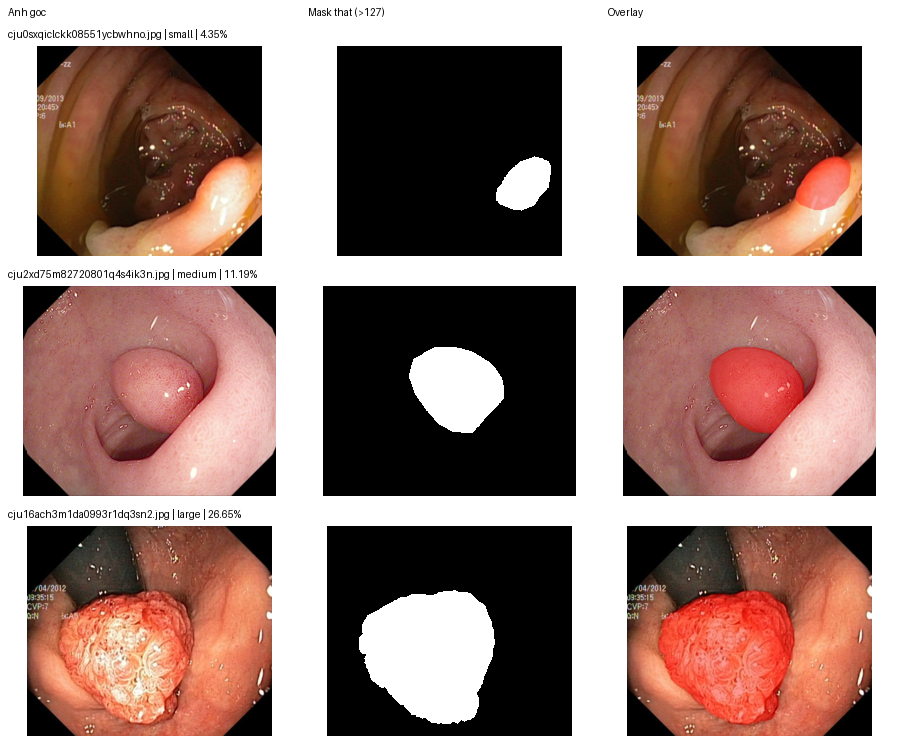

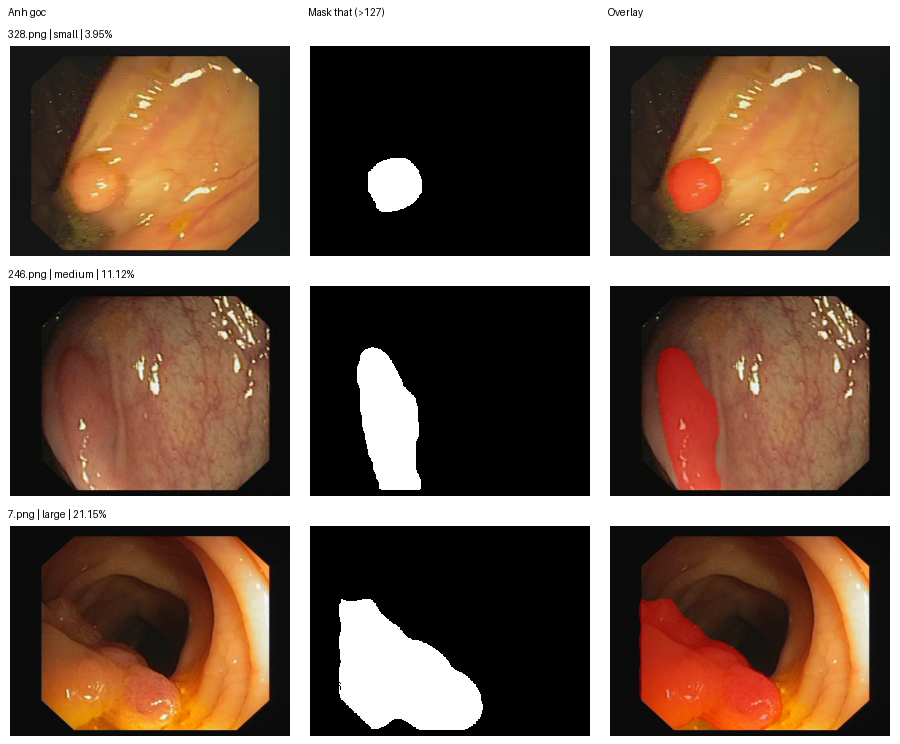

In [2]:
rows_by_dataset = scan_datasets(PROJECT_ROOT)
resolution_rows = resolution_statistics(rows_by_dataset)
size_rows, thresholds, size_rule = assign_size_groups(PROJECT_ROOT, rows_by_dataset)
print("Quy tắc diện tích:", size_rule, thresholds)
for path in save_sample_figures(PROJECT_ROOT, rows_by_dataset, PROJECT_ROOT / "logs/dataset_statistics"):
    from PIL import Image
    with Image.open(path) as image:
        display(image.copy())


## 2.2 — Sàng lọc ảnh trùng và gần trùng

Module `duplicates.py` sử dụng các biểu diễn sau:

| Phương pháp | Biểu diễn | Ý nghĩa |
| --- | --- | --- |
| SHA-256 tệp | Byte của tệp gốc | Phát hiện tệp giống hệt nhau |
| SHA-256 RGB64 | Ảnh RGB 64×64 | Phát hiện biểu diễn thu nhỏ giống nhau; không chứng minh ảnh gốc giống hệt |
| dHash | Ảnh grayscale 9×8 | Sàng lọc theo chênh lệch độ sáng lân cận |
| pHash | Ảnh grayscale 32×32 | Sàng lọc theo cấu trúc tần số thấp |

Ảnh tính hash được resize giữ tỷ lệ bằng Lanczos và padding đen ở giữa. Padding được chia đều; phần dư một pixel nằm bên phải hoặc phía dưới. Các kích thước này phục vụ sàng lọc, khác với đầu vào 256×256 của mô hình.

Một cặp được đưa vào danh sách ứng viên khi khoảng cách **dHash ≤6 hoặc pHash ≤6**. Đây là điều kiện sàng lọc, không phải kết luận ảnh trùng. Padding và phiên bản thư viện có thể ảnh hưởng kết quả; thông tin phương pháp được lưu trong `logs/duplicate_check/screening_manifest.json`.

Các quyết định được đọc từ `splits/duplicate_review.csv` và nhận cập nhật từ `logs/duplicate_check/review_decisions.csv`. Cặp đã có quyết định được giữ lại kể cả khi nằm ngoài ngưỡng mới. Hai cặp lịch sử có quyết định dự phòng `unsure`; các ứng viên mới khác giữ trạng thái `pending` cho đến khi được rà.

| Trạng thái | Diễn giải |
| --- | --- |
| `confirmed` | Đã xác nhận quan hệ gần trùng qua rà ảnh |
| `different` | Được đánh giá là khác nhau; không chứng minh độc lập theo bệnh nhân |
| `unsure` | Chưa đủ bằng chứng kết luận; bảo vệ cùng nhóm khi tạo split |
| `pending` | Chưa có quyết định rà |

Việc dùng lại split hiện có không tự giải quyết các ứng viên `pending`. Các giới hạn này được ghi trong báo cáo kiểm tra.

In [3]:
fingerprints = fingerprint_datasets(PROJECT_ROOT, rows_by_dataset)
exact_groups, near_candidates = screen_duplicates(PROJECT_ROOT, fingerprints)
review_rows = load_review(PROJECT_ROOT, near_candidates)
confirmed_groups = save_confirmed_groups(PROJECT_ROOT, fingerprints, exact_groups, review_rows)
print("Nhóm confirmed:", len(confirmed_groups))


Số cặp được so sánh: 1,298,466
Kvasir-SEG: 0 nhóm trùng file | 0 nhóm trùng RGB 64x64 | 217 cặp nghi gần trùng
cross_dataset: 0 nhóm trùng file | 0 nhóm trùng RGB 64x64 | 129 cặp nghi gần trùng
CVC-ClinicDB: 0 nhóm trùng file | 0 nhóm trùng RGB 64x64 | 2144 cặp nghi gần trùng
Thư mục kết quả: D:\DHCN\HK5\DL\Medical-Image-Segmentation\logs\duplicate_check
Kvasir-SEG {'confirmed': 8, 'pending': 158, 'different': 44, 'unsure': 7}
cross_dataset {'different': 109, 'pending': 20}
CVC-ClinicDB {'confirmed': 20, 'pending': 2124}
Nhóm confirmed: 24


### Kiểm tra trực quan các cặp ứng viên

Ô dưới hiển thị từng cặp theo phạm vi (`scope`), trang hoặc `pair_id`, với tối đa sáu cặp mỗi trang. Khi rà, cần đối chiếu nếp mô, mạch máu và vùng xung quanh polyp; hình dạng polyp tương tự không đủ để xác nhận cùng cảnh.

Để bổ sung quyết định, cập nhật CSV và chạy lại ô tổng hợp ở mục 2.2. Việc rà ảnh có thể thực hiện độc lập với quá trình kiểm tra tự động split đã lưu. Không sử dụng kết quả mô hình để quyết định nhãn rà.

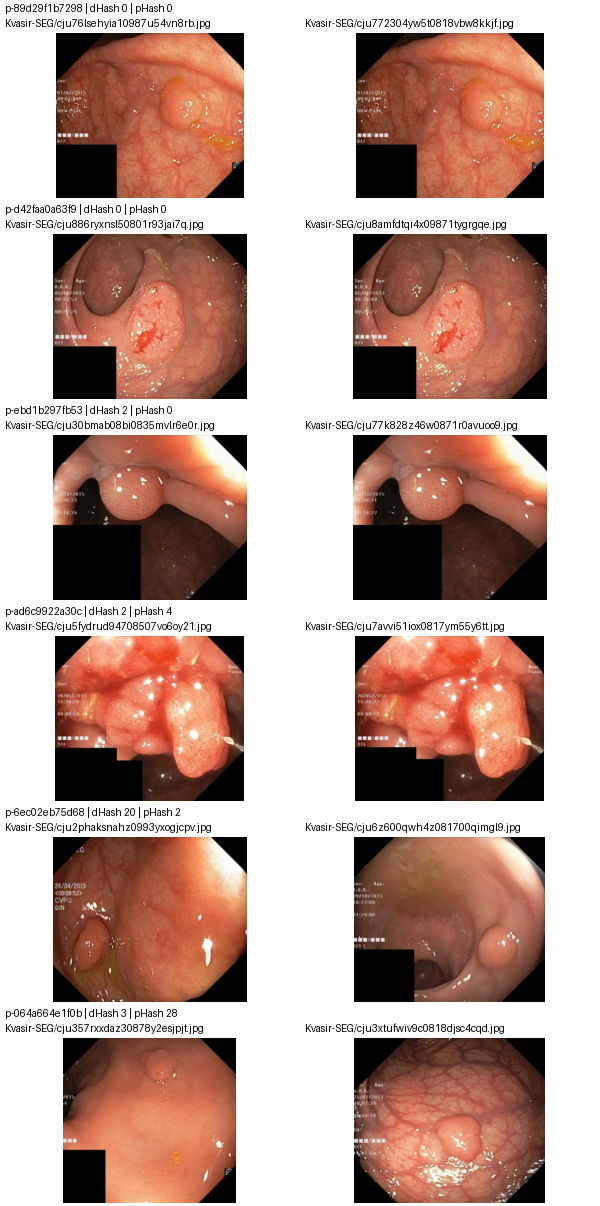

In [4]:
REVIEW_SCOPE = "Kvasir-SEG"
REVIEW_PAGE = 1
REVIEW_PAIR_ID = ""
PAIRS_PER_PAGE = 6
if REVIEW_PAIR_ID.strip():
    selected = [r for r in near_candidates if r["pair_id"] == REVIEW_PAIR_ID.strip().lower()]
    if not selected:
        raise ValueError("Không tìm thấy pair_id.")
else:
    candidates = [r for r in near_candidates if r["scope"] == REVIEW_SCOPE]
    pages = (len(candidates) + PAIRS_PER_PAGE - 1) // PAIRS_PER_PAGE
    if pages and not 1 <= REVIEW_PAGE <= pages:
        raise ValueError(f"Chọn trang trong khoảng 1–{pages}.")
    offset = (REVIEW_PAGE - 1) * PAIRS_PER_PAGE
    selected = candidates[offset:offset + PAIRS_PER_PAGE]
if selected:
    display(draw_candidate_pairs(PROJECT_ROOT / "data", selected))
else:
    print("Không có cặp để xem.")


## 2.3 — Kiểm tra các tập dữ liệu đã cố định

Nếu đã có đủ bốn danh sách split, module `audit.py` kiểm tra:

- Danh sách không rỗng, ID duy nhất và không giao nhau giữa các tập.
- ID tham chiếu đến ảnh đang có trong dữ liệu.
- Checksum ảnh–mask khớp manifest nguồn.
- Các quan hệ trùng chính xác và `confirmed`/`unsure` được cung cấp có bị tách tập hay không.
- Số ứng viên Kvasir hoặc cross-dataset chưa có quyết định.

Quy trình giữ nguyên danh sách split. Báo cáo mang trạng thái `provisional` nếu còn ứng viên chưa rà hoặc phát hiện xung đột giữa các tập. Trạng thái này cho phép hoàn tất bước kiểm tra tự động nhưng không xác nhận đã loại trừ mọi khả năng rò rỉ dữ liệu.

Nếu chưa có đủ danh sách split, `splitting.py` tạo kế hoạch theo nhóm với seed 42. Các liên kết `confirmed` và `unsure` được bảo vệ cùng nhóm; ứng viên chưa rà trong Kvasir/cross-dataset vẫn chặn việc chốt kế hoạch mới.

In [5]:
from src.datasets.audit import audit_fixed_splits
USE_FIXED_SPLITS = all((PROJECT_ROOT / 'splits' / name).exists() for name in
    ('kvasir_train.txt', 'kvasir_val.txt', 'kvasir_test.txt', 'clinicdb_external.txt'))
if USE_FIXED_SPLITS:
    summary = audit_fixed_splits(PROJECT_ROOT, fingerprints, exact_groups, review_rows)
else:
    plan = build_split_plan(fingerprints, exact_groups, review_rows, seed=42)


{
  "status": "provisional",
  "operation": "audit_existing_splits_no_repartition",
  "split_counts": {
    "train": 700,
    "val": 150,
    "test": 150,
    "external": 612
  },
  "source_files_verified": 3224,
  "known_protected_pair_conflicts": [],
  "unresolved_internal_or_cross_pairs": 178,
  "review_counts": {
    "CVC-ClinicDB": {
      "confirmed": 20,
      "pending": 2124
    },
    "Kvasir-SEG": {
      "confirmed": 8,
      "pending": 158,
      "different": 44,
      "unsure": 7
    },
    "cross_dataset": {
      "different": 109,
      "pending": 20
    }
  },
  "limitations": "Pending candidates are not confirmed duplicates; patient independence is not verified."
}


## 2.4 — Bảo toàn và xuất danh sách split

Ở chế độ kiểm tra split đã có, ô dưới không ghi lại các danh sách hoặc metadata chia tập. Kết quả kiểm tra được lưu riêng, giúp bảo toàn đầu vào của các thí nghiệm đã thực hiện.

Ở chế độ tạo split mới, module đối chiếu checksum nguồn trước khi xuất danh sách ID, nhóm liên quan, quyết định rà và manifest. Mỗi dòng trong danh sách chứa ID không có đuôi ảnh. Nếu danh sách đã có nội dung khác, quá trình ghi sẽ dừng thay vì tự ghi đè.

In [8]:
if not USE_FIXED_SPLITS:
    manifest = write_split_artifacts(PROJECT_ROOT, rows_by_dataset, fingerprints, review_rows, plan)


## 2.5 — Tổng hợp kết quả kiểm tra

Khi sử dụng split hiện có, kết quả được lưu tại `results/tables/step2_fixed_split_audit.json`, gồm số mẫu mỗi tập, số tệp đã kiểm tra checksum, xung đột được phát hiện và thống kê trạng thái rà. Nhánh này không tạo lại báo cáo chia tập mới; các hình khảo sát ở mục 2.1 vẫn được lưu trong `logs/dataset_statistics/`.

Khi tạo split mới thành công, `reporting.py` xuất bảng thống kê, hình minh họa và tổng kết trong `results/`. Ngưỡng diện tích được tính từ tập train, không từ validation/test.

CVC-ClinicDB được giữ cho đánh giá ngoài, không dùng để lựa chọn checkpoint, loss hoặc siêu tham số. Không khẳng định độc lập theo bệnh nhân khi chưa có metadata xác minh.

In [7]:
if not USE_FIXED_SPLITS:
    summary = write_reports(PROJECT_ROOT, rows_by_dataset, resolution_rows, review_rows, plan, manifest)
else:
    print('Audit saved: results/tables/step2_fixed_split_audit.json')


Audit saved: results/tables/step2_fixed_split_audit.json


## Đầu ra và giới hạn diễn giải

| Đầu ra | Vị trí |
| --- | --- |
| Danh sách split và quyết định rà dùng chung | `splits/` |
| Báo cáo kiểm tra split hiện có | `results/tables/step2_fixed_split_audit.json` |
| Thống kê và hình khảo sát ban đầu | `logs/dataset_statistics/` |
| Ứng viên, trạng thái rà và cấu hình sàng lọc | `logs/duplicate_check/` |
| Bảng/hình báo cáo khi tạo split mới | `results/tables/`, `results/figures/` |

Output trong notebook ghi nhận kết quả của lần chạy được lưu. Khi dữ liệu, phương pháp hash hoặc quyết định rà thay đổi, cần chạy lại các mục liên quan để cập nhật kết quả. Báo cáo `provisional` cần được trình bày cùng các giới hạn chưa rà, không diễn giải là đã xác minh toàn bộ dữ liệu không trùng.

Bước tiếp theo là kiểm tra preprocessing và DataLoader trong notebook 03, sau đó huấn luyện M1 trong notebook 04 trên cùng split đã cố định.